# Thin-film lithium niobate adiabatic coupler in BeamZ

Recreate the device in Flexcompute's [Tidy3D adiabatic LN coupler example](https://www.flexcompute.com/tidy3d/examples/notebooks/AdiabaticCouplerLN/): launch TE₀ and TM₀ separately and measure transfer between the outer waveguides.

**Status: prepared for the simulation PC. No physical simulation results have been generated or validated.** All mode solves and FDTD runs are disabled by default. Run All performs only analytical geometry plots, resource arithmetic, and construction of a small simulation specification.

The companion [benchmark notebook](tfln_adiabatic_coupler_benchmark.ipynb) adds mesh/time/boundary checks and optional Tidy3D comparison. Both use [the shared setup](../tfln_coupler.py).

## 1. Environment and execution controls

Use this checkout's BeamZ development environment with NumPy and Matplotlib and a Python notebook kernel. On the simulation PC, install the checkout according to the repository README, select that environment's kernel, and verify the intended JAX/CUDA backend before enabling runs. `jax` is the portable default; select `cuda_streamed` explicitly only when that backend is installed and supported. There is no cloud dependency for this example.

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np

# Works from the repository root, beamz/, or examples/notebooks/.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "examples/tfln_coupler.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the BeamZ checkout; retain examples/tfln_coupler.py.")
sys.path.insert(0, str(ROOT))

import beamz as bz
from examples.tfln_coupler import (
    REFERENCE_URL, CouplerConfig, build_simulation, load_spectrum,
    modal_spectrum, plane_centres, resource_estimate, save_spectrum,
    waveguide_vertices,
)

plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"te": "#2463A0", "tm": "#B46B12"}

In [2]:
RUN_MODE_PREVIEW = False
RUN_SIMULATIONS = False
BACKEND = "jax"
INCLUDE_FIELD = True  # Full xy DFT plane; turn off to reduce monitor memory.
CONFIG = CouplerConfig()
OUTPUT_DIR = ROOT / "data/tfln_adiabatic_coupler/example"
print(json.dumps(asdict(CONFIG), indent=2))

{
  "length_um": 2000.0,
  "width_um": 1.0,
  "height_um": 0.6,
  "d12_um": 2.0,
  "d23_um": 1.0,
  "buffer_um": 10.0,
  "n_o": 2.211,
  "n_e": 2.138,
  "n_clad": 1.44,
  "wavelength_min_um": 1.45,
  "wavelength_max_um": 1.65,
  "frequency_count": 101,
  "dx_um": 0.06,
  "domain_y_um": 8.0,
  "domain_z_um": 5.2,
  "pml_um": 0.6,
  "run_time_s": 4e-11
}


## 2. Reference geometry and material orientation

The device has three strips, each 1 µm wide and 0.6 µm thick, embedded in silica. Its coupling region is 2000 µm long. The two outer guides are parallel; the middle guide changes its centre-to-centre distance to the lower guide from 2 µm to 1 µm. The distances are **not edge gaps**. There is no residual LN slab in this particular reference.

With propagation along simulation (x), the optic axis is simulation (y):

[
arepsilon_r=operatorname{diag}(2.211^2,;2.138^2,;2.211^2),qquad n_{mathrm{SiO_2}}=1.44.
]

These are constant-index approximations matching the reference, not a dispersive Sellmeier model. This example exercises diagonal anisotropy, not arbitrary off-diagonal dispersion or the Pockels effect. Coordinates are translated to centre the device at the origin; crystal orientation is unchanged.

The numerical setup differs explicitly from the published notebook:

- Full 3D domain and four candidate modes with polarization ordering replace mirror-symmetry mode selection. Inspect the selected TE₀/TM₀ profiles before trusting results.
- A uniform grid replaces Tidy3D's automatic grid. `farjadpour_diagonal` smoothing preserves the diagonal material path used by BeamZ's modal sources and monitors.
- The transverse domain is enlarged to contain the full 3 µm × 3.6 µm mode aperture plus CPML clearance. Absorbing-layer thickness stays approximately fixed in physical units during refinement.
- An upstream mode monitor measures incident power at every frequency. Transfer is normalized by that measured forward power.
- The band is stated explicitly as 1.45–1.65 µm, sampled uniformly in frequency. Its frequency midpoint is not exactly (c/(1.55,mumathrm{m})).

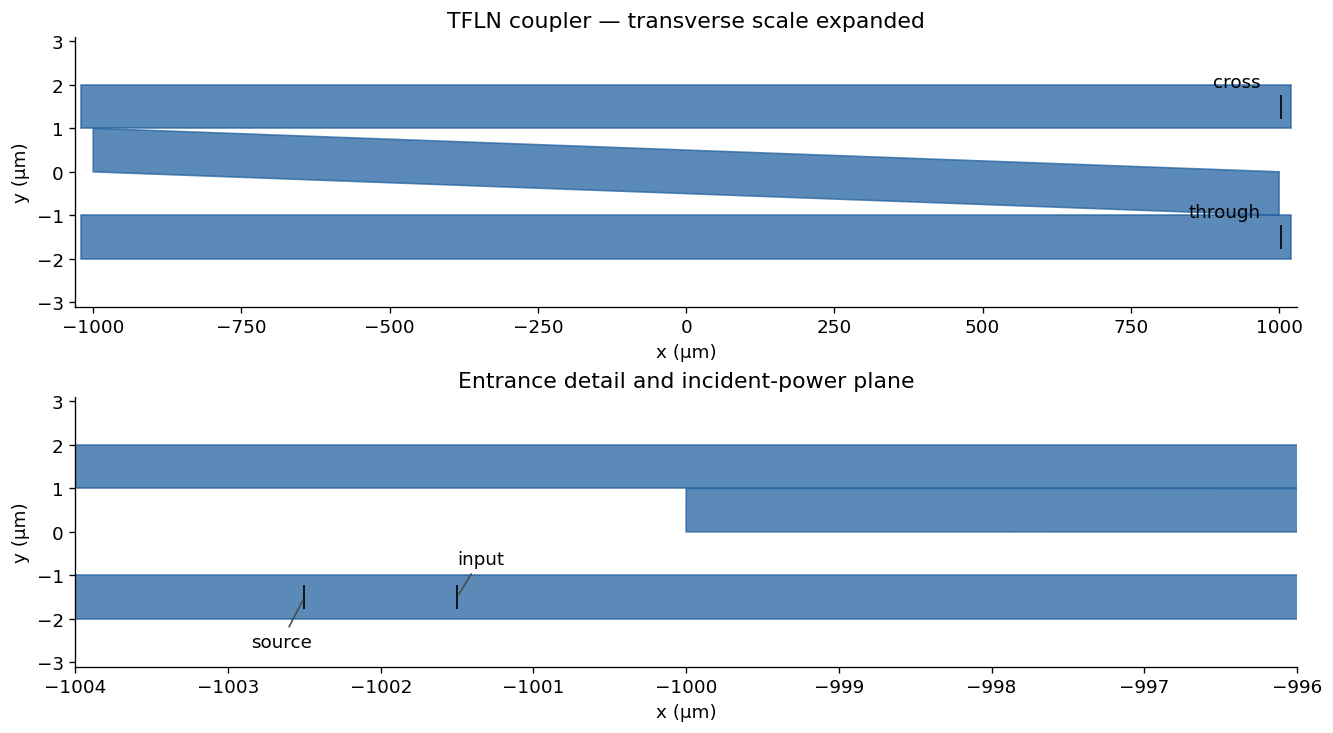

LN epsilon diagonal: [4.888521 4.571044 4.888521]
Reference: https://www.flexcompute.com/tidy3d/examples/notebooks/AdiabaticCouplerLN/


In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), constrained_layout=True)
centres = plane_centres(CONFIG)
for ax in axes:
    for vertices in waveguide_vertices(CONFIG):
        ax.fill(vertices[:, 0], vertices[:, 1], color=COLORS["te"], alpha=0.75)
    ax.set(xlabel="x (µm)", ylabel="y (µm)", ylim=(-3.1, 3.1))
axes[0].set(xlim=(-CONFIG.length_um / 2 - 30, CONFIG.length_um / 2 + 30),
            title="TFLN coupler — transverse scale expanded")
for name in ("cross", "through"):
    x, y, _ = centres[name]
    axes[0].plot(x, y, "|", color="black", markersize=14)
    axes[0].annotate(name, (x, y), xytext=(-12, 12),
                     textcoords="offset points", ha="right")
x0 = -CONFIG.length_um / 2
axes[1].set(xlim=(x0 - 4, x0 + 4), title="Entrance detail and incident-power plane")
for name, shift in (("source", (-14, -30)), ("input", (14, 20))):
    x, y, _ = centres[name]
    axes[1].plot(x, y, "|", color="black", markersize=14)
    axes[1].annotate(name, (x, y), xytext=shift, textcoords="offset points",
                     ha="center", arrowprops={"arrowstyle": "-", "color": "0.3"})
plt.show()
print("LN epsilon diagonal:", np.array([CONFIG.n_o, CONFIG.n_e, CONFIG.n_o])**2)
print("Reference:", REFERENCE_URL)

## 3. Resource estimate and setup sanity checks

The estimate below does not rasterize the full structure. Six float32 field arrays are only a **lower bound** on storage; material tensors, coefficients, Yee staggering, CPML, DFT monitors, temporary buffers, host copies, and compilation increase peak memory considerably. A full run may require more memory than a single desktop GPU.

The small specification below is only an API/placement check. Its shortened geometry and 20 fs time window are **not a physical surrogate** for the 2 mm coupler. No mode solve, compilation, or time stepping takes place.

In [4]:
print(json.dumps(resource_estimate(CONFIG), indent=2))
sanity_config = replace(CONFIG, length_um=8.0, dx_um=0.1,
                        frequency_count=3, run_time_s=20e-15)
for polarization in ("te", "tm"):
    specification = build_simulation(sanity_config, polarization)
    assert specification.is_3d
    assert len(specification.sources) == 1
    assert {m.name for m in specification.monitors} == {"input", "cross", "through"}
    assert specification.sources[0].mode_spec.polarization == polarization
    offset = np.asarray(specification.coordinate_offset)
    actual_source = np.asarray(specification.sources[0].center) - offset
    np.testing.assert_allclose(actual_source / bz.um, plane_centres(sanity_config)["source"])
    assert specification.num_steps > 0
print("TE/TM specification and source placement checks passed; no solver executed.")

{
  "shape_xyz": [
    33667,
    134,
    87
  ],
  "cells": 392489886,
  "six_float32_fields_GiB_lower_bound": 8.772832587361336,
  "vacuum_CFL_steps_estimate": 349668
}
TE/TM specification and source placement checks passed; no solver executed.


## 4. Optional source-mode preview

On the simulation PC, enable `RUN_MODE_PREVIEW` first. Use a short domain with the same entrance cross section to avoid allocating the entire 2 mm device just to inspect its modes. This preview still rasterizes a 3D region and solves eigenproblems. Check that selected mode 0 is guided, fundamental, and predominantly Ey for TE or Ez for TM. Polarization preference orders candidates; it is not a proof of correct mode selection.

In [5]:
if RUN_MODE_PREVIEW:
    from beamz.analysis import mode_data_to_dataframe
    from beamz.analysis.plotting import plot_mode_field_components
    from IPython.display import display

    preview_config = replace(CONFIG, length_um=20.0, frequency_count=3)
    for polarization in ("te", "tm"):
        preview = build_simulation(preview_config, polarization)
        # The public mode-preview API expects centred coordinates.
        source = preview.sources[0].shifted(tuple(-v for v in preview.coordinate_offset))
        modes = source.solve_modes(preview, freqs=[CONFIG.freq0])
        display(mode_data_to_dataframe(modes))
        plot_mode_field_components(modes, field_names=("Ey", "Ez"),
                                   mode_indices=(0,), f=CONFIG.freq0,
                                   val="abs", figsize=(9, 3.5), show=False)
        plt.suptitle(f"Selected {polarization.upper()} entrance mode")
        plt.show()
else:
    print("Mode preview deferred to the simulation PC.")

Mode preview deferred to the simulation PC.


## 5. Run both polarizations and save spectra

Enable `RUN_SIMULATIONS` only on the simulation PC after inspecting the resource estimate and source modes. The two runs are sequential. Each completed spectrum is saved immediately with the complete configuration, normalization, and timing metadata. The optional field plot is generated before releasing that run's large result object.

The 40 ps window follows the reference. It must still be checked against a longer run in the benchmark notebook; completing a fixed time window is not evidence of convergence.

In [6]:
spectra = {}
if RUN_SIMULATIONS:
    import gc
    import jax
    import platform
    import subprocess

    for polarization in ("te", "tm"):
        start = time.perf_counter()
        simulation = build_simulation(CONFIG, polarization, include_field=INCLUDE_FIELD)
        result = simulation.run(backend=BACKEND, progress=True, performance=True)
        run_wall_s = time.perf_counter() - start
        spectra[polarization] = modal_spectrum(result.mode, CONFIG)
        path = save_spectrum(
            OUTPUT_DIR, "beamz", polarization, CONFIG, spectra[polarization],
            backend=BACKEND, beamz_version=bz.__version__, jax_version=jax.__version__,
            python_version=platform.python_version(), devices=[str(d) for d in jax.devices()],
            git_commit=subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ROOT, text=True).strip(),
            worktree_dirty=bool(subprocess.check_output(["git", "status", "--porcelain"], cwd=ROOT, text=True)),
            include_field=INCLUDE_FIELD, run_wall_s=run_wall_s,
            performance=asdict(result.performance) if result.performance else None,
        )
        print("Saved", path)
        if INCLUDE_FIELD:
            result.plot_field("field", "E", frequency=CONFIG.freq0, val="abs^2", cmap="magma")
            plt.title(f"{polarization.upper()}: electric-field intensity")
            plt.show()
        del result, simulation
        jax.clear_caches()
        gc.collect()
else:
    print("FDTD runs disabled. No simulation results are claimed.")

FDTD runs disabled. No simulation results are claimed.


## 6. Coupling spectra

For the selected mode, (T_{
m cross}=|a_{
m cross}^{+}|^2/|a_{
m input}^{+}|^2), with analogous through power and input reflection. Weak incident bins are NaN, never silently converted to zero. Values are not clipped to [0, 1]. The sum of these three selected-mode powers is a diagnostic, not complete energy closure: other modes, the other input rail, and radiation are not included.

The reference reports greater than 90% transfer for both polarizations across its band. That is a qualitative target from the publication, **not a measured BeamZ result or a convergence tolerance**.

In [7]:
if spectra:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    for polarization, spectrum in spectra.items():
        order = np.argsort(spectrum["wavelength_um"])
        wl = spectrum["wavelength_um"][order]
        style = "-" if polarization == "te" else "--"
        axes[0].plot(wl, spectrum["T_cross"][order], style,
                     color=COLORS[polarization], label=polarization.upper())
        for metric, ls in (("T_through", "-"), ("R_input", ":")):
            axes[1].plot(wl, spectrum[metric][order], ls, color=COLORS[polarization],
                         label=f"{polarization.upper()} {metric}")
    axes[0].axhline(0.9, color="0.4", ls=":", label="Reference's qualitative 90% target")
    axes[0].set(ylabel="Forward modal transfer / incident power", title="Outer-guide transfer")
    axes[1].set(ylabel="Selected modal power / incident power", title="Through and reflected power")
    for ax in axes:
        ax.set_xlabel("Wavelength (µm)")
        ax.legend(fontsize=9)
    plt.show()
else:
    print("No spectra yet. Enable runs above on the simulation PC.")

No spectra yet. Enable runs above on the simulation PC.


## Handoff

Keep the two notebooks and `examples/tfln_coupler.py` together in the checkout. No external results are bundled. First inspect the modes, then run one polarization, then both; use the benchmark notebook to check spatial resolution, runtime, and absorbing boundaries before drawing device-performance conclusions.

**Deferred:** FDTD execution, source-mode validation, field/spectrum inspection, GPU memory measurement, and comparison against numerical Tidy3D data. This notebook does not implement material dispersion or electro-optic modulation.